<a href="https://colab.research.google.com/github/anvithagcs24-stack/BISLAB/blob/main/WEEK6_BISLAB_GREY_WOLF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration: 1 Best Fitness: 34.878
Iteration: 2 Best Fitness: 34.878
Iteration: 3 Best Fitness: 34.878
Iteration: 4 Best Fitness: 34.636
Iteration: 5 Best Fitness: 34.636
Iteration: 6 Best Fitness: 34.636
Iteration: 7 Best Fitness: 33.827
Iteration: 8 Best Fitness: 33.827
Iteration: 9 Best Fitness: 33.827
Iteration: 10 Best Fitness: 33.827
Iteration: 11 Best Fitness: 33.827
Iteration: 12 Best Fitness: 33.827
Iteration: 13 Best Fitness: 33.827
Iteration: 14 Best Fitness: 32.885
Iteration: 15 Best Fitness: 32.885
Iteration: 16 Best Fitness: 32.885
Iteration: 17 Best Fitness: 32.527
Iteration: 18 Best Fitness: 31.286
Iteration: 19 Best Fitness: 31.286
Iteration: 20 Best Fitness: 31.286
Iteration: 21 Best Fitness: 31.286
Iteration: 22 Best Fitness: 31.15
Iteration: 23 Best Fitness: 31.15
Iteration: 24 Best Fitness: 31.15
Iteration: 25 Best Fitness: 31.15
Iteration: 26 Best Fitness: 31.15
Iteration: 27 Best Fitness: 31.15
Iteration: 28 Best Fitness: 31.15
Iteration: 29 Best Fitness: 31.15
It

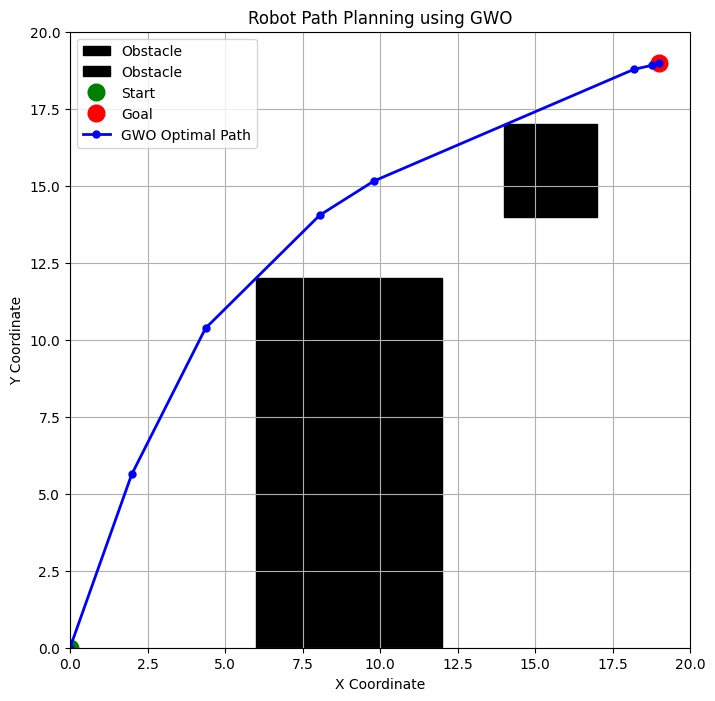

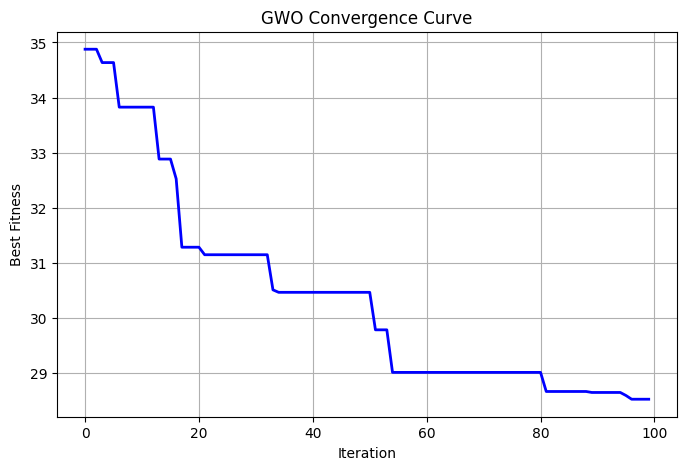


Optimal Robot Path Coordinates:
Point 1: (0.00, 0.00)
Point 2: (1.99, 5.62)
Point 3: (4.37, 10.37)
Point 4: (8.05, 14.04)
Point 5: (9.80, 15.15)
Point 6: (18.18, 18.78)
Point 7: (18.77, 18.91)
Point 8: (19.00, 19.00)


In [1]:

# ROBOT PATH PLANNING USING GREY WOLF OPTIMIZER (GWO)

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# 1. Initialize Environment

GRID_SIZE = 20

START = np.array([0.0, 0.0])
GOAL = np.array([19.0, 19.0])

OBSTACLES = [
    (6, 0, 12, 12),
    (14, 14, 17, 17)
]

N_WAYPOINTS = 6
DIM = N_WAYPOINTS * 2

# 2. Collision Detection

def is_collision(point):

    x, y = point

    for x1, y1, x2, y2 in OBSTACLES:
        if x1 <= x <= x2 and y1 <= y <= y2:
            return True

    return False


def segment_collision(p1, p2):

    for t in np.linspace(0, 1, 101):

        point = p1 + t * (p2 - p1)

        if is_collision(point):
            return True

    return False


# 3. Calculate Path Distance

def path_length(path):

    points = np.vstack([START, path, GOAL])

    distance = 0

    for i in range(len(points)-1):

        distance += np.linalg.norm(
            points[i+1] - points[i]
        )

    return distance


# 4. Fitness Function

def fitness_function(position):

    path = position.reshape(N_WAYPOINTS, 2)

    points = np.vstack([START, path, GOAL])

    distance = path_length(path)

    collisions = 0

    for i in range(len(points)-1):

        if segment_collision(points[i], points[i+1]):
            collisions += 1

    return distance + 10000 * collisions


# 5. Grey Wolf Optimizer

def GWO(SearchAgents_no, Max_iter, dim):

    Positions = np.random.uniform(
        0, GRID_SIZE-1,
        (SearchAgents_no, dim)
    )

    # Initialize one candidate path around the obstacle
    Positions[0] = np.array([
        [3, 8],
        [5, 14],
        [9, 15],
        [13, 13],
        [13, 18],
        [18, 18]
    ]).flatten()

    Alpha_pos = np.zeros(dim)
    Beta_pos = np.zeros(dim)
    Delta_pos = np.zeros(dim)

    Alpha_score = float("inf")
    Beta_score = float("inf")
    Delta_score = float("inf")

    convergence = []

    for t in range(Max_iter):

        # Fitness evaluation
        for i in range(SearchAgents_no):

            Positions[i] = np.clip(
                Positions[i], 0, GRID_SIZE-1
            )

            fitness = fitness_function(Positions[i])

            if fitness < Alpha_score:

                Delta_score = Beta_score
                Delta_pos = Beta_pos.copy()

                Beta_score = Alpha_score
                Beta_pos = Alpha_pos.copy()

                Alpha_score = fitness
                Alpha_pos = Positions[i].copy()

            elif fitness < Beta_score:

                Delta_score = Beta_score
                Delta_pos = Beta_pos.copy()

                Beta_score = fitness
                Beta_pos = Positions[i].copy()

            elif fitness < Delta_score:

                Delta_score = fitness
                Delta_pos = Positions[i].copy()

        # Update parameter a
        a = 2 - 2 * (t / Max_iter)

        # Update positions
        for i in range(SearchAgents_no):

            for j in range(dim):

                r1, r2 = np.random.random(2)

                A1 = 2*a*r1 - a
                C1 = 2*r2

                D_alpha = abs(
                    C1*Alpha_pos[j] - Positions[i,j]
                )

                X1 = Alpha_pos[j] - A1*D_alpha

                r1, r2 = np.random.random(2)

                A2 = 2*a*r1 - a
                C2 = 2*r2

                D_beta = abs(
                    C2*Beta_pos[j] - Positions[i,j]
                )

                X2 = Beta_pos[j] - A2*D_beta

                r1, r2 = np.random.random(2)

                A3 = 2*a*r1 - a
                C3 = 2*r2

                D_delta = abs(
                    C3*Delta_pos[j] - Positions[i,j]
                )

                X3 = Delta_pos[j] - A3*D_delta

                Positions[i,j] = (X1+X2+X3)/3

            Positions[i] = np.clip(
                Positions[i], 0, GRID_SIZE-1
            )

        convergence.append(Alpha_score)

        print("Iteration:", t+1,
              "Best Fitness:", round(Alpha_score, 3))

    return Alpha_pos, Alpha_score, convergence


# 6. Execute GWO

SearchAgents_no = 30
Max_iter = 100

np.random.seed(42)

best_position, best_fitness, convergence = GWO(
    SearchAgents_no, Max_iter, DIM
)

best_path = best_position.reshape(N_WAYPOINTS, 2)

# 7. Calculate Final Path

points = np.vstack([START, best_path, GOAL])

total_distance = path_length(best_path)

collision_count = sum(
    segment_collision(points[i], points[i+1])
    for i in range(len(points)-1)
)

print("\n----- FINAL RESULTS -----")
print("Best Fitness:", round(best_fitness, 3))
print("Total Path Distance:", round(total_distance, 3))
print("Collision Segments:", collision_count)

if collision_count == 0:
    print("Result: Collision-free path found")
else:
    print("Result: Path contains collisions")


# 8. Plot Robot Environment and Optimal Path

fig, ax = plt.subplots(figsize=(8, 8))

ax.set_xlim(0, GRID_SIZE)
ax.set_ylim(0, GRID_SIZE)

for x1, y1, x2, y2 in OBSTACLES:

    ax.add_patch(Rectangle(
        (x1, y1),
        x2-x1,
        y2-y1,
        color='black',
        label='Obstacle'
    ))

ax.plot(
    START[0], START[1],
    'go', markersize=12, label='Start'
)

ax.plot(
    GOAL[0], GOAL[1],
    'ro', markersize=12, label='Goal'
)

ax.plot(
    points[:,0], points[:,1],
    'b-o', linewidth=2,
    markersize=5, label='GWO Optimal Path'
)

ax.set_title("Robot Path Planning using GWO")
ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")
ax.grid(True)
ax.legend()
plt.show()


# 9. Plot Convergence Curve

plt.figure(figsize=(8,5))

plt.plot(
    convergence,
    color='blue',
    linewidth=2
)

plt.title("GWO Convergence Curve")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.grid(True)
plt.show()


# 10. Display Final Path Coordinates

print("\nOptimal Robot Path Coordinates:")

for i, point in enumerate(points):

    print(
        f"Point {i+1}: "
        f"({point[0]:.2f}, {point[1]:.2f})"
    )
